# PaddleOCR (PP-OCRv6 recognition) cho OCR chữ laser trên PCB

Notebook này **thay PARSeq (bản tự cài bằng PyTorch) bằng PaddleOCR làm framework**: kiến trúc, hàm loss, optimizer, post-process và pretrained weights đều lấy từ **repo PaddleOCR chính thức**. Phần dữ liệu, split, nhãn, evaluator chung, quy tắc chọn checkpoint, seed và cách lưu vết giữ nguyên như notebook PARSeq để **so sánh trực tiếp** được (cùng `SPLIT HASH`).

## Model card (cũng được in ra và lưu thành `model_card.json` khi chạy)

| Hạng mục | Giá trị |
|---|---|
| **Framework** | PaddleOCR **3.7.0** (git tag `v3.7.0`, commit `b03f46425e8ff4442b268ce449e3eef758146cd4`, phát hành 11/06/2026) |
| **Deep-learning engine** | PaddlePaddle **3.2.0** (`paddlepaddle-gpu`, CUDA 12.6), phiên bản được ghim trong tài liệu cài đặt của chính tag v3.7.0. Phiên bản thực tế được ghi lại khi chạy |
| **Model nhận dạng** | **PP-OCRv6_medium_rec** (mặc định, đổi qua `CFG.rec_model`) |
| **Kiến trúc** | `SVTR_LCNet`: backbone **PPLCNetV4** (medium), neck **LightSVTR**, head **MultiHead** = CTC + NRTR (suy luận chỉ dùng nhánh CTC) |
| **Config gốc** | `configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml` (sha256 được ghi khi chạy) |
| **Pretrained weights** | `PP-OCRv6_medium_rec_pretrained.pdparams` (training weights chính thức của PaddleOCR), tải từ `https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_pretrained.pdparams`. **sha256, kích thước và số tensor nạp được** được tính và ghi khi chạy |
| **Từ điển ký tự** | Từ điển khai báo trong config của chính model đó, **giữ nguyên** nên toàn bộ head pretrained được nạp. Với `PP-OCRv6_medium_rec` là `ppocr/utils/dict/ppocrv6_dict.txt` (+ khoảng trắng `use_space_char`). Các cỡ khác có thể dùng từ điển riêng (ví dụ tiny: `ppocrv6_tiny_dict.txt`). Tên và sha256 từ điển được ghi vào model card khi chạy |
| **Fine-tune** | Toàn bộ mô hình, từ pretrained trên, bằng train.csv của nhóm |

Các model khác trong `MODEL_ZOO`: `PP-OCRv6_small_rec`, `PP-OCRv6_tiny_rec`, `PP-OCRv5_server_rec`, `PP-OCRv5_mobile_rec`. URL pretrained và đường dẫn config của tất cả đều lấy từ tài liệu và config trong repo ở tag `v3.7.0`.

## ⚠ Giới hạn đã biết: dữ liệu này là ảnh nhiều dòng, còn PP-OCR là bộ nhận dạng **một dòng**

- Trên bộ dữ liệu của nhóm: **46,6% nhãn có nhiều dòng** (trung bình 1,73 dòng/ảnh) và ảnh gần **vuông** (tỉ lệ w/h trung vị ≈ 0,95; hơn một nửa là ảnh đứng).
- Backbone PPLCNetV4 **gập chiều cao về 1** rồi đọc theo chiều rộng (CTC), ảnh đầu vào chuẩn là cao 48 px, rộng 320 px. Khác với PARSeq (ViT đọc ảnh 2D), kiến trúc này **không được thiết kế để đọc chữ xếp nhiều dòng**.
- Vì vậy notebook này là một **baseline PaddleOCR đúng chuẩn (stock)**, chưa tối ưu cho bố cục nhiều dòng. Ký tự xuống dòng được ánh xạ thành một ký tự placeholder trong chuỗi, và cell phân tích lỗi (mục 11) **báo kết quả riêng cho nhãn 1 dòng và nhiều dòng** để bạn thấy rõ ảnh hưởng. Nếu cần bố cục 2D, PaddleOCR 3.7.0 cũng có `ParseQ` (2D, `rec_vit_parseq.yml`); xem mục 12.

## 0. Tuân thủ cấu hình chung bắt buộc

| Hạng mục | Cách notebook thực hiện | Nơi thực hiện |
|---|---|---|
| Dataset | Giữ **đủ 2.120 / 455 dòng**, không loại mẫu nào | §2 |
| Split | 90/10 theo capture gốc, `split_seed=42` riêng. Xuất `split_manifest.csv` và SHA256 | §2 |
| Chống leakage | Bản `_aug` đi theo capture gốc. Val chỉ đánh giá mẫu gốc. `assert` train ∩ val = ∅ | §2 |
| Test | Chỉ chạy khi `CFG.final_test = True`, giữ nguyên 455 mẫu | §10 |
| Nhãn | Không `upper()`/`strip()`. Chỉ chuẩn hóa NFC và line ending. Xuống dòng → ký tự placeholder **chỉ trong file nhãn của PaddleOCR**, được đổi ngược khi tính metric | §2, §3 |
| Metric | `evaluator.py` chung: CER corpus-level (chính), WER, SeqAcc, NED + params, FPS, peak VRAM. Đánh giá trên **toàn bộ** val/test (kể cả nhãn rỗng), không dùng vòng eval của PaddleOCR (nó bỏ qua nhãn rỗng/quá dài) | §5, §6, §10 |
| Checkpoint | Val CER thấp nhất. Hòa → val loss thấp hơn → epoch sớm hơn | §6 |
| Seed | Screening `[42]`, xác nhận `[42, 43, 44]` | §8 |
| Precision | `auto`: BF16 nếu GPU hỗ trợ, ngược lại FP16 (AMP O1 + GradScaler). Ghi vào config | §1, §6 |
| Reproducibility | Mỗi run lưu `config.json`, `env.json`, `model_card.json`, `train.log`, `history.csv`, `best.pdparams`, `val/test_predictions.csv`, split hash, git commit | §6 |
| **Ghi rõ model / phiên bản / pretrained** | Model card ở đầu notebook, in ra bằng `print_model_card()` và lưu thành JSON cho từng run | §4 |

## Cài đặt môi trường (chạy một lần)

Cell dưới cài **PaddlePaddle** đúng phiên bản đã ghim và clone **PaddleOCR đúng tag `v3.7.0`**, rồi kiểm tra commit hash. Nếu đã có sẵn thì bỏ qua. Trên Kaggle cần bật GPU và Internet. Nếu vừa cài PaddlePaddle xong mà `import paddle` lỗi, hãy khởi động lại kernel rồi chạy lại.

In [1]:
import os, sys, shutil, subprocess
from pathlib import Path

PADDLEOCR_TAG    = "v3.7.0"
PADDLEOCR_COMMIT = "b03f46425e8ff4442b268ce449e3eef758146cd4"
PADDLE_VERSION   = "3.2.0"
PADDLE_GPU_INDEX = "https://www.paddlepaddle.org.cn/packages/stable/cu126/"      # CUDA 12.6 (như tài liệu cài đặt của tag v3.7.0)
REPO_DIR         = Path(os.environ.get("PADDLEOCR_DIR", "PaddleOCR"))

def sh(cmd, check=True):
    print("$", " ".join(cmd))
    return subprocess.run(cmd, check=check)

# 1) PaddlePaddle
try:
    import paddle
    print("PaddlePaddle đã có:", paddle.__version__)
except ImportError:
    has_gpu = shutil.which("nvidia-smi") is not None
    if has_gpu:
        sh([sys.executable, "-m", "pip", "install", "-q", f"paddlepaddle-gpu=={PADDLE_VERSION}", "-i", PADDLE_GPU_INDEX])
    else:
        sh([sys.executable, "-m", "pip", "install", "-q", f"paddlepaddle=={PADDLE_VERSION}"])
    import paddle

# 2) PaddleOCR đúng tag
if not (REPO_DIR / "ppocr").exists():
    sh(["git", "clone", "--depth", "1", "--branch", PADDLEOCR_TAG, "https://github.com/PaddlePaddle/PaddleOCR.git", str(REPO_DIR)])
    sh([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements.txt")])
head = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("PaddleOCR commit:", head)
if head != PADDLEOCR_COMMIT:
    print(f"[CẢNH BÁO] commit {head} khác commit đã ghim của tag {PADDLEOCR_TAG} ({PADDLEOCR_COMMIT}). Kết quả có thể không tái lập.")
sys.path.insert(0, str(REPO_DIR.resolve()))

$ /usr/bin/python3 -m pip install -q paddlepaddle-gpu==3.2.0 -i https://www.paddlepaddle.org.cn/packages/stable/cu126/


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires nvidia-cudnn-cu12==9.19.0.56; platform_system == "Linux", but you have nvidia-cudnn-cu12 9.5.1.17 which is incompatible.
torch 2.11.0+cu128 requires nvidia-cusparselt-cu12==0.7.1; platform_system == "Linux", but you have nvidia-cusparselt-cu12 0.6.3 which is incompatible.
torch 2.11.0+cu128 requires nvidia-nccl-cu12==2.28.9; platform_system == "Linux", but you have nvidia-nccl-cu12 2.25.1 which is incompatible.
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


$ git clone --depth 1 --branch v3.7.0 https://github.com/PaddlePaddle/PaddleOCR.git PaddleOCR


Cloning into 'PaddleOCR'...
Note: switching to 'b03f46425e8ff4442b268ce449e3eef758146cd4'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



$ /usr/bin/python3 -m pip install -q -r PaddleOCR/requirements.txt
PaddleOCR commit: b03f46425e8ff4442b268ce449e3eef758146cd4


In [2]:
import math, random, time, copy, string, re, json, hashlib, platform, contextlib, unicodedata, datetime, urllib.request
import numpy as np
import pandas as pd
import yaml
import cv2
import PIL
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

import paddle
import paddle.nn.functional as F
from ppocr.modeling.architectures import build_model
from ppocr.losses import build_loss
from ppocr.optimizer import build_optimizer
from ppocr.postprocess import build_post_process
from ppocr.data import build_dataloader
from ppocr.data.imaug import create_operators, transform
import ppocr.data.imaug as ppocr_imaug
from ppocr.utils.save_load import load_pretrained_params
from ppocr.utils.logging import get_logger

pd.set_option("display.width", 200)
print("paddle", paddle.__version__, "| cuda:", paddle.version.cuda() if paddle.device.is_compiled_with_cuda() else None)

Skipping import of the encryption module.


/kaggle/working/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1239: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/kaggle/working/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1479: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/kaggle/working/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1523: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"


paddle 3.2.0 | cuda: 12.6


## 1. Cấu hình

- `rec_model`: model nhận dạng, chọn trong `MODEL_ZOO` (config + URL pretrained chính thức). Mặc định `PP-OCRv6_medium_rec`.
- `use_pretrained`: nạp pretrained weights chính thức rồi fine-tune. `False` = train từ đầu (chỉ để ablation).
- `rec_image_shape`: `[3, 48, 320]` là chuẩn của PP-OCR. Backbone PPLCNetV4 cần **chiều cao 48** khi suy luận (xem `PPLCNetV4.forward`), nên không đổi chiều cao.
- `lr`: 1e-4 cho fine-tune (config gốc dùng 5e-4 cho train từ đầu với batch lớn). `batch_size`: 32.
- `split_mode`, `split_seed`, `val_ratio`, `seeds`, `final_test`, `precision`: như notebook PARSeq.
- `rot90`, `rot90_angles`: Rot90 augmentation (op tự viết, chèn ngay sau `DecodeImage`, chỉ train). `augment`: `RecAug` chuẩn của PaddleOCR (TIA, blur, jitter...).

In [3]:
def locate(name, is_dir=False, roots=(".", "data", "/kaggle/input", "/content", "/content/drive")):
    for r in roots:
        if not os.path.exists(r):
            continue
        for dp, dns, fns in os.walk(r):
            if (name in dns) if is_dir else (name in fns):
                return Path(dp) / name
    return None

# ---------------------------------------------------------------- MODEL ZOO: model nhận dạng + config + pretrained chính thức
_BOS = "https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/"
MODEL_ZOO = {
    "PP-OCRv6_medium_rec": dict(family="PP-OCRv6", config="configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml", pretrained_url=_BOS + "PP-OCRv6_medium_rec_pretrained.pdparams"),
    "PP-OCRv6_small_rec":  dict(family="PP-OCRv6", config="configs/rec/PP-OCRv6/PP-OCRv6_small_rec.yml",  pretrained_url=_BOS + "PP-OCRv6_small_rec_pretrained.pdparams"),
    "PP-OCRv6_tiny_rec":   dict(family="PP-OCRv6", config="configs/rec/PP-OCRv6/PP-OCRv6_tiny_rec.yml",   pretrained_url=_BOS + "PP-OCRv6_tiny_rec_pretrained.pdparams"),
    "PP-OCRv5_server_rec": dict(family="PP-OCRv5", config="configs/rec/PP-OCRv5/PP-OCRv5_server_rec.yml", pretrained_url=_BOS + "PP-OCRv5_server_rec_pretrained.pdparams"),
    "PP-OCRv5_mobile_rec": dict(family="PP-OCRv5", config="configs/rec/PP-OCRv5/PP-OCRv5_mobile_rec.yml", pretrained_url=_BOS + "PP-OCRv5_mobile_rec_pretrained.pdparams"),
}

class CFG:
    # --- đường dẫn: mặc định tự dò, sửa tay nếu cần ---
    train_csv = Path("/kaggle/input/datasets/binbinkin/pcb-dataset/train.csv")
    test_csv  = Path("/kaggle/input/datasets/binbinkin/pcb-dataset/test.csv")
    img_root  = Path("/kaggle/input/datasets/binbinkin/pcb-dataset/multi_view_v2")
    out_dir   = Path("outputs_paddleocr")
    pretrain_dir = Path("pretrained")

    all_views   = ["DF_path", "PO_path", "CO_path"]
    train_views = ["DF_path"]
    label_col   = "title"

    # --- dữ liệu chính thức (chỉ để kiểm tra, không lọc) ---
    expected_train_rows = 2120
    expected_train_orig = 1060
    expected_test_rows  = 455

    # --- nhãn ---
    literal_backslash_n_to_newline = True
    max_label_len = 64                       # hằng số CHUNG của nhóm; ghi vào Global.max_text_length và NRTRHead
    newline_candidates = ("¶", "|", "§", "↵", "⏎")   # ký tự thay cho '\n' trong file nhãn PaddleOCR (phải có trong dict, chưa dùng trong nhãn)

    # --- framework và model (xem model card) ---
    paddleocr_tag, paddleocr_commit, paddle_version = PADDLEOCR_TAG, PADDLEOCR_COMMIT, PADDLE_VERSION
    repo_dir        = REPO_DIR
    rec_model       = "PP-OCRv6_medium_rec"
    use_pretrained  = True
    rec_image_shape = [3, 48, 320]

    # --- train ---
    batch_size    = 32
    epochs        = 100
    min_epochs    = 25
    patience      = 20
    lr            = 1e-4
    warmup_epochs = 3
    augment       = True                 # RecAug chuẩn của PaddleOCR
    rot90         = True                 # Rot90 augmentation (chỉ train)
    rot90_angles  = (0, 90, 180, 270)
    precision     = "auto"               # "auto" | "fp16" | "bf16" | "fp32"
    num_workers   = 2

    # --- split (như notebook PARSeq) ---
    split_mode  = "capture"              # "capture" = OFFICIAL | "board" = chỉ phân tích generalization
    val_ratio   = 0.10
    board_val_ratio = 0.15
    split_seed  = 42
    split_manifest_in  = None
    expected_split_hash = None

    seeds = [42]                         # screening. Xác nhận: [42, 43, 44]
    seed  = 42
    final_test = False
    git_commit = None

if not CFG.train_csv.exists(): CFG.train_csv = locate("train.csv") or CFG.train_csv
if not CFG.test_csv.exists():  CFG.test_csv  = locate("test.csv")  or CFG.test_csv
if not CFG.img_root.exists():  CFG.img_root  = locate("multi_view_v2", is_dir=True) or CFG.img_root
print("train_csv:", CFG.train_csv, "\ntest_csv :", CFG.test_csv, "\nimg_root :", CFG.img_root)

if CFG.split_mode == "board":
    CFG.out_dir = Path("outputs_paddleocr_board_analysis")
    print("!!! split_mode = 'board': chỉ dùng phân tích generalization, ghi vào", CFG.out_dir)
CFG.out_dir.mkdir(parents=True, exist_ok=True)
VIEW_NAME = {"DF_path": "DF", "PO_path": "PO", "CO_path": "CO"}

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); paddle.seed(seed)
    try: paddle.set_flags({"FLAGS_cudnn_deterministic": True})
    except Exception: pass

USE_GPU = paddle.device.is_compiled_with_cuda() and paddle.device.cuda.device_count() > 0
DEVICE = paddle.set_device("gpu:0" if USE_GPU else "cpu")

def resolve_precision(p):
    if p != "auto":
        return p
    if not USE_GPU:
        return "fp32"
    try:
        if paddle.device.cuda.get_device_capability()[0] >= 8 and paddle.amp.is_bfloat16_supported():
            return "bf16"
    except Exception:
        pass
    return "fp16"                                  # T4 (sm_75) và các GPU cũ hơn

set_seed(CFG.seed)
CFG.precision_resolved = resolve_precision(CFG.precision)
print("device:", DEVICE, "| precision:", CFG.precision_resolved, "| model:", CFG.rec_model)

train_csv: /kaggle/input/datasets/binbinkin/pcb-dataset/train.csv 
test_csv : /kaggle/input/datasets/binbinkin/pcb-dataset/test.csv 
img_root : /kaggle/input/datasets/binbinkin/pcb-dataset/multi_view_v2
device: Place(gpu:0) | precision: fp16 | model: PP-OCRv6_medium_rec


## 2. Đọc dữ liệu, chuẩn hóa nhãn, chia train/val

**Không loại mẫu nào.** Nhãn rỗng, nhãn có ký tự lạ hay nhãn dài đều được giữ và chỉ **báo cáo số lượng** (nếu loại thì train/test không còn khớp bộ dữ liệu chính thức của nhóm).

**Quy tắc chuẩn hóa nhãn** (`norm_label`, chung cho cả nhóm):
1. Đọc CSV ở dạng chuỗi, `keep_default_na=False` (để nhãn như `NA` hay `NULL` không bị biến thành NaN). Ô trống → `""`.
2. Unicode NFC.
3. `\r\n` và `\r` thật → `\n`.
4. (cờ `CFG.literal_backslash_n_to_newline`) chuỗi 2 ký tự `\n` chữ thường → xuống dòng thật.
5. **Không** `strip()`, **không** `upper()`, **không** xóa ký tự.

**Split:** cột `capture_id` = tên file DF bỏ đuôi `_aug` và bỏ token view (DF/PO/CO). Chọn ngẫu nhiên 10% capture **gốc** vào val (seed `CFG.split_seed`). Mọi bản `_aug` của capture đó cũng thuộc val nhưng **không dùng để train hay đánh giá**.

In [4]:
def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p):  return sha256_bytes(Path(p).read_bytes())

def read_csv_raw(path):
    # dtype=str + keep_default_na=False: không để pandas tự biến "NA"/"NULL"... thành NaN
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

train_raw = read_csv_raw(CFG.train_csv)
test_raw  = read_csv_raw(CFG.test_csv)
print("train.csv:", train_raw.shape, "| test.csv:", test_raw.shape)
if len(train_raw) != CFG.expected_train_rows or len(test_raw) != CFG.expected_test_rows:
    raise ValueError(f"Số dòng không khớp bộ chính thức: train {len(train_raw)} (cần {CFG.expected_train_rows}), "
                     f"test {len(test_raw)} (cần {CFG.expected_test_rows})")

DATA_HASHES = {"train.csv": sha256_file(CFG.train_csv), "test.csv": sha256_file(CFG.test_csv)}
print("sha256 train.csv:", DATA_HASHES["train.csv"][:16], "| test.csv:", DATA_HASHES["test.csv"][:16])

def norm_label(s):
    """Chỉ chuẩn hóa encoding + line ending. KHÔNG strip, KHÔNG đổi hoa/thường, KHÔNG xóa ký tự."""
    s = "" if s is None or (isinstance(s, float) and np.isnan(s)) else str(s)
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    if CFG.literal_backslash_n_to_newline:
        s = s.replace("\\r\\n", "\n").replace("\\n", "\n")
    return s

IMG_INDEX = {}
for dp, _, fns in os.walk(CFG.img_root):
    for fn in fns:
        IMG_INDEX.setdefault(fn, os.path.join(dp, fn))
print(f"Tìm thấy {len(IMG_INDEX)} file trong {CFG.img_root}")

def resolve_path(p):
    p = str(p).replace("\\", "/")
    for base in (CFG.img_root, Path("."), Path("data")):
        cand = Path(base) / p
        if cand.exists():
            return str(cand)
    return IMG_INDEX.get(os.path.basename(p))

LEGACY_CHARS = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789 \n+-.")     # chỉ để THỐNG KÊ, không dùng để lọc

def prepare(df, name):
    df = df.copy().reset_index(drop=True)
    df.insert(0, "row_id", np.arange(len(df)))
    df["title_raw"] = df[CFG.label_col]
    df[CFG.label_col] = df["title_raw"].map(norm_label)
    for v in CFG.all_views:
        df[v + "_abs"] = df[v].map(resolve_path)
    missing = df[[v + "_abs" for v in CFG.all_views]].isna().any(axis=1)
    if missing.any():
        raise FileNotFoundError(f"[{name}] {missing.sum()} dòng thiếu ảnh, ví dụ: "
                                f"{df.loc[missing, CFG.all_views].head(3).values.tolist()}")
    L = df[CFG.label_col]
    odd = L.map(lambda s: not set(s) <= LEGACY_CHARS)
    print(f"[{name}] {len(df)} dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: {(L == '').sum()} | "
          f"có chữ thường: {L.str.contains('[a-z]').sum()} | ký tự ngoài A-Z0-9 +-.: {odd.sum()} | còn dấu '\\': {L.str.contains(chr(92), regex=False).sum()}")
    if odd.sum():
        print("   ví dụ (đã chuẩn hóa):", [repr(x) for x in L[odd].head(6)])
    return df

train_all = prepare(train_raw, "train")
test_df   = prepare(test_raw,  "test")

# ---- capture_id / is_aug / board -------------------------------------------------------------------------
AUG_RE  = re.compile(r"(^|_)aug\d*(?=_|$)", re.I)
VIEW_RE = re.compile(r"(^|_)(DF|PO|CO)(?=_|$)")

def _stem(p): return os.path.splitext(os.path.basename(str(p).replace("\\", "/")))[0]

def parse_capture(df):
    stems = df[CFG.all_views[0]].map(_stem)
    df["is_aug"] = np.logical_or.reduce([df[v].map(lambda p: bool(AUG_RE.search(_stem(p)))).values for v in CFG.all_views])
    df["capture_id"] = stems.map(lambda s: VIEW_RE.sub("", AUG_RE.sub("", s)).strip("_"))
    df["board"] = df["capture_id"].map(lambda s: s.split("_")[0])      # như get_group cũ: "100_05_..." -> "100"
    return df

train_all = parse_capture(train_all)
test_df   = parse_capture(test_df)

n_orig, n_aug = int((~train_all.is_aug).sum()), int(train_all.is_aug.sum())
print(f"[train] gốc: {n_orig} | _aug: {n_aug} | capture gốc duy nhất: {train_all.loc[~train_all.is_aug, 'capture_id'].nunique()} | "
      f"board: {train_all.board.nunique()}")
print("   ví dụ tên file -> capture_id:", [(os.path.basename(a), b, bool(c)) for a, b, c in
      train_all[[CFG.all_views[0], "capture_id", "is_aug"]].sample(4, random_state=0).values])
if n_orig != CFG.expected_train_orig or n_aug != CFG.expected_train_rows - CFG.expected_train_orig:
    print(f"[CẢNH BÁO] kỳ vọng {CFG.expected_train_orig} gốc + {CFG.expected_train_rows - CFG.expected_train_orig} _aug. "
          "Kiểm tra lại quy ước đặt tên _aug (AUG_RE) trước khi chia split.")
orig_ids = set(train_all.loc[~train_all.is_aug, "capture_id"])
orphan = train_all[train_all.is_aug & ~train_all.capture_id.isin(orig_ids)]
if len(orphan):
    print(f"[CẢNH BÁO] {len(orphan)} bản _aug không tìm thấy capture gốc, ví dụ:", orphan[CFG.all_views[0]].head(3).tolist())
if test_df.is_aug.any():
    print(f"[CẢNH BÁO] test có {int(test_df.is_aug.sum())} file _aug (test chính thức chỉ gồm mẫu gốc)")

train.csv: (2120, 4) | test.csv: (455, 4)
sha256 train.csv: 017963db097cc067 | test.csv: 20dc321533062396
Tìm thấy 7782 file trong /kaggle/input/datasets/binbinkin/pcb-dataset/multi_view_v2
[train] 2120 dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: 20 | có chữ thường: 2 | ký tự ngoài A-Z0-9 +-.: 4 | còn dấu '\': 2
   ví dụ (đã chuẩn hóa): ["'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'", "'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[test] 455 dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: 4 | có chữ thường: 3 | ký tự ngoài A-Z0-9 +-.: 3 | còn dấu '\': 1
   ví dụ (đã chuẩn hóa): ["'E8002D\\\\Ncjc1w1'", "'EM638325TS-5G\\nl403705a0t205 11M\\nETRONTECH'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[train] gốc: 1060 | _aug: 1060 | capture gốc duy nhất: 1060 | board: 34
   ví dụ tên file -> capture_id: [('52_05_DF_7.bmp', '52_05_7', False), ('101_06_DF_3_aug.bmp', '101_06_3', True), ('54_09_DF_6.bmp', '54_09_6', False), ('102_02_DF_13.bmp', '102_02_13',

In [5]:
# ---------------------------------------------------------------- SPLIT (một lần, cố định, có manifest + hash)
def manifest_hash(m):
    s = m[["row_id", "capture_id", "is_aug", "split"]].sort_values("row_id").to_csv(index=False, lineterminator="\n")
    return sha256_bytes(s.encode("utf-8"))

def make_split(df):
    rng = np.random.RandomState(CFG.split_seed)                    # seed của split, KHÔNG phụ thuộc seed huấn luyện
    if CFG.split_mode == "capture":
        key, ratio = "capture_id", CFG.val_ratio
        units = sorted(df.loc[~df.is_aug, key].unique())           # chỉ bốc thăm trên capture GỐC
    elif CFG.split_mode == "board":
        key, ratio = "board", CFG.board_val_ratio
        units = sorted(df[key].unique())
    else:
        raise ValueError("split_mode phải là 'capture' hoặc 'board'")
    units = np.array(units); rng.shuffle(units)
    n_val = max(1, int(round(len(units) * ratio)))
    val_units = set(units[:n_val].tolist())
    return np.where(df[key].isin(val_units), "val", "train")      # bản _aug đi theo capture/board của nó

if CFG.split_manifest_in and Path(CFG.split_manifest_in).exists():
    shared = pd.read_csv(CFG.split_manifest_in, dtype={"split": str})
    if set(shared.row_id) != set(train_all.row_id):
        raise ValueError("split_manifest_in không khớp train.csv (khác tập row_id)")
    train_all["split"] = train_all.row_id.map(shared.set_index("row_id")["split"])
    print("[split] nạp manifest dùng chung của nhóm:", CFG.split_manifest_in)
else:
    train_all["split"] = make_split(train_all)
    print(f"[split] tạo mới | mode={CFG.split_mode} | split_seed={CFG.split_seed}")
if not set(train_all.split) <= {"train", "val"}:
    raise ValueError("cột split chỉ được nhận 'train' hoặc 'val'")

manifest = train_all[["row_id", "capture_id", "board", "is_aug", "split"] + CFG.all_views].copy()
SPLIT_HASH = manifest_hash(manifest)
sfx = "" if CFG.split_mode == "capture" else "_board"
manifest.to_csv(CFG.out_dir / f"split_manifest{sfx}.csv", index=False)
(CFG.out_dir / f"split_hash{sfx}.txt").write_text(SPLIT_HASH + "\n")
if CFG.expected_split_hash and CFG.expected_split_hash != SPLIT_HASH:
    raise ValueError(f"Split hash khác của nhóm!\n  nhóm : {CFG.expected_split_hash}\n  của bạn: {SPLIT_HASH}")

tr_rows  = train_all[train_all.split == "train"]
val_rows = train_all[train_all.split == "val"]
# ---- chống leakage ----
assert not (set(tr_rows.capture_id) & set(val_rows.capture_id)), "LEAK: capture xuất hiện ở cả train và val"
assert not (set(tr_rows.row_id) & set(val_rows.row_id))
if CFG.split_mode == "board":
    assert not (set(tr_rows.board) & set(val_rows.board)), "LEAK: board xuất hiện ở cả train và val"
assert len(tr_rows) + len(val_rows) == len(train_all)

train_df = tr_rows.reset_index(drop=True)                           # gốc + _aug
val_df   = val_rows[~val_rows.is_aug].reset_index(drop=True)        # CHỈ mẫu gốc
val_aug_unused = int(val_rows.is_aug.sum())                         # _aug của capture val: không train, không đánh giá

overlap = set(test_df.capture_id) & set(train_all.capture_id)
if overlap:
    print(f"[CẢNH BÁO] {len(overlap)} capture_id của test trùng với train.csv, ví dụ: {sorted(overlap)[:3]}")

print(f"train: {len(train_df)} dòng ({int((~train_df.is_aug).sum())} gốc + {int(train_df.is_aug.sum())} _aug) | "
      f"val: {len(val_df)} mẫu gốc (+{val_aug_unused} _aug không dùng) | test: {len(test_df)}")
print(f"tỉ lệ capture gốc train/val: {(~train_df.is_aug).sum()}/{len(val_df)} = "
      f"{(~train_df.is_aug).sum() / (len(val_df) + (~train_df.is_aug).sum()):.3f}/{len(val_df) / (len(val_df) + (~train_df.is_aug).sum()):.3f}")
print("SPLIT HASH:", SPLIT_HASH)
print("-> để khóa split, đặt CFG.expected_split_hash = '%s...' (đủ 64 ký tự)" % SPLIT_HASH[:16])

[split] tạo mới | mode=capture | split_seed=42
train: 1908 dòng (954 gốc + 954 _aug) | val: 106 mẫu gốc (+106 _aug không dùng) | test: 455
tỉ lệ capture gốc train/val: 954/106 = 0.900/0.100
SPLIT HASH: 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
-> để khóa split, đặt CFG.expected_split_hash = '495f92f5e14f1048...' (đủ 64 ký tự)


## 4. Model nhận dạng, từ điển ký tự và pretrained weights (model card)

Cell này:
1. Đọc **config chính thức** của `CFG.rec_model` từ repo (ghi sha256).
2. Tải **pretrained weights chính thức** (nếu chưa có), tính **sha256 và kích thước**.
3. Chọn **ký tự placeholder cho `\n`**: một ký tự *đã có trong từ điển của PaddleOCR* và *chưa xuất hiện trong nhãn train/val*. Dùng từ điển gốc nguyên vẹn nên **toàn bộ head pretrained (kể cả lớp phân loại CTC/NRTR) được nạp**.
4. Ghi `model_card.json`.

In [6]:
def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

ZOO = MODEL_ZOO[CFG.rec_model]
CONFIG_PATH = CFG.repo_dir / ZOO["config"]
assert CONFIG_PATH.exists(), f"không thấy config {CONFIG_PATH}"
BASE_CFG = yaml.safe_load(open(CONFIG_PATH, encoding="utf-8"))
DICT_PATH = (CFG.repo_dir / BASE_CFG["Global"]["character_dict_path"]).resolve()
assert DICT_PATH.exists(), DICT_PATH

# ---- pretrained weights chính thức ----
def ensure_pretrained():
    if not CFG.use_pretrained:
        return None
    CFG.pretrain_dir.mkdir(parents=True, exist_ok=True)
    dst = CFG.pretrain_dir / f"{CFG.rec_model}_pretrained.pdparams"
    if not dst.exists():
        print("Tải pretrained weights:", ZOO["pretrained_url"])
        urllib.request.urlretrieve(ZOO["pretrained_url"], str(dst) + ".part")
        os.replace(str(dst) + ".part", dst)
    return dst

PRETRAINED_PATH = ensure_pretrained()

# ---- ký tự placeholder cho xuống dòng ----
dict_chars = [l.rstrip("\n") for l in open(DICT_PATH, encoding="utf-8")]
used_chars = set("".join(train_df[CFG.label_col])) | set("".join(val_df[CFG.label_col]))
NL_CHAR = next((c for c in CFG.newline_candidates if c in dict_chars and c not in used_chars), None)
if NL_CHAR is None:
    raise ValueError("Không có ký tự placeholder nào trong CFG.newline_candidates vừa có trong từ điển vừa chưa dùng trong nhãn. Thêm ứng viên khác.")
unknown = (used_chars | set("".join(test_df[CFG.label_col]))) - set(dict_chars) - {" ", "\n"}
print(f"từ điển: {DICT_PATH.name} ({len(dict_chars)} ký tự) | placeholder cho '\\n': {NL_CHAR!r}")
print("ký tự trong nhãn KHÔNG có trong từ điển (mô hình không thể dự đoán, vẫn tính vào metric):", sorted(unknown) or "không có")

# ---- model card ----
def build_model_card():
    card = dict(
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        framework=dict(name="PaddleOCR", version=CFG.paddleocr_tag.lstrip("v"), git_tag=CFG.paddleocr_tag,
                       git_commit_expected=CFG.paddleocr_commit,
                       git_commit_actual=subprocess.run(["git", "-C", str(CFG.repo_dir), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip(),
                       repo="https://github.com/PaddlePaddle/PaddleOCR"),
        engine=dict(name="paddlepaddle", version=paddle.__version__, cuda=paddle.version.cuda() if USE_GPU else None,
                    pinned=CFG.paddle_version, device=str(DEVICE)),
        recognition_model=dict(name=CFG.rec_model, family=ZOO["family"],
                               algorithm=BASE_CFG["Architecture"]["algorithm"],
                               backbone=BASE_CFG["Architecture"]["Backbone"],
                               head=[list(h)[0] for h in BASE_CFG["Architecture"]["Head"]["head_list"]],
                               loss=[list(l)[0] for l in BASE_CFG["Loss"]["loss_config_list"]],
                               config_file=ZOO["config"], config_sha256=sha256_file(CONFIG_PATH)),
        character_dict=dict(file=str(DICT_PATH.relative_to(CFG.repo_dir.resolve())), n_chars=len(dict_chars),
                            sha256=sha256_file(DICT_PATH), use_space_char=bool(BASE_CFG["Global"].get("use_space_char", True)),
                            newline_placeholder=NL_CHAR),
        pretrained_weights=dict(used=bool(CFG.use_pretrained), url=ZOO["pretrained_url"] if CFG.use_pretrained else None,
                                local_file=str(PRETRAINED_PATH) if PRETRAINED_PATH else None,
                                size_bytes=PRETRAINED_PATH.stat().st_size if PRETRAINED_PATH else None,
                                sha256=sha256_file(PRETRAINED_PATH) if PRETRAINED_PATH else None,
                                note="training weights chính thức của PaddleOCR (.pdparams); fine-tune toàn bộ mô hình"),
        input=dict(image_shape=CFG.rec_image_shape, max_text_length=CFG.max_label_len),
    )
    return card

MODEL_CARD = build_model_card()

def print_model_card(card=None):
    c = card or MODEL_CARD
    rows = [("Framework", f"PaddleOCR {c['framework']['version']} (tag {c['framework']['git_tag']}, commit {c['framework']['git_commit_actual'][:12]})"),
            ("Engine", f"PaddlePaddle {c['engine']['version']} (CUDA {c['engine']['cuda']}, ghim {c['engine']['pinned']})"),
            ("Model nhận dạng", f"{c['recognition_model']['name']} | {c['recognition_model']['algorithm']} | backbone {c['recognition_model']['backbone']['name']} ({c['recognition_model']['backbone'].get('model_size')}) | head {'+'.join(c['recognition_model']['head'])}"),
            ("Config", f"{c['recognition_model']['config_file']} (sha256 {c['recognition_model']['config_sha256'][:16]}…)"),
            ("Từ điển", f"{c['character_dict']['file']} ({c['character_dict']['n_chars']} ký tự, sha256 {c['character_dict']['sha256'][:16]}…) | placeholder xuống dòng {c['character_dict']['newline_placeholder']!r}"),
            ("Pretrained", (f"{Path(c['pretrained_weights']['local_file']).name} | {c['pretrained_weights']['size_bytes'] / 2**20:.1f} MB | sha256 {c['pretrained_weights']['sha256'][:16]}…\n" + " " * 18 + f"{c['pretrained_weights']['url']}") if c['pretrained_weights']['used'] else "KHÔNG (train từ đầu)")]
    if "params_M" in c.get("model_stats", {}):
        s = c["model_stats"]
        rows.append(("Tham số / nạp pretrained", f"{s['params_M']:.2f}M tham số | nạp {s['loaded_tensors']}/{s['total_tensors']} tensor (bỏ qua do khác shape: {s['skipped_shape_mismatch']}, thiếu trong file: {s['missing_in_file']})"))
    print("=" * 100)
    for k, v in rows:
        print(f"{k:<24}{v}")
    print("=" * 100)

print_model_card()
(CFG.out_dir / "model_card.json").write_text(json.dumps(MODEL_CARD, ensure_ascii=False, indent=2), encoding="utf-8")

Tải pretrained weights: https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_pretrained.pdparams
từ điển: ppocrv6_dict.txt (18708 ký tự) | placeholder cho '\n': '¶'
ký tự trong nhãn KHÔNG có trong từ điển (mô hình không thể dự đoán, vẫn tính vào metric): không có
Framework               PaddleOCR 3.7.0 (tag v3.7.0, commit b03f46425e8f)
Engine                  PaddlePaddle 3.2.0 (CUDA 12.6, ghim 3.2.0)
Model nhận dạng         PP-OCRv6_medium_rec | SVTR_LCNet | backbone PPLCNetV4 (medium) | head CTCHead+NRTRHead
Config                  configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml (sha256 5ebee6044fc713b6…)
Từ điển                 ppocr/utils/dict/ppocrv6_dict.txt (18708 ký tự, sha256 b5f2bfe2bdd94484…) | placeholder xuống dòng '¶'
Pretrained              PP-OCRv6_medium_rec_pretrained.pdparams | 221.9 MB | sha256 c4a110423c23739f…
                  https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_

1739

## 3. Dữ liệu cho PaddleOCR: file nhãn, augmentation và config

- PaddleOCR đọc dữ liệu nhận dạng từ **file nhãn** dạng `đường_dẫn<TAB>nhãn`, mỗi dòng một mẫu. Vì nhãn của nhóm có nhiều dòng, ký tự `\n` được thay bằng `NL_CHAR` **chỉ trong file nhãn**, và đổi ngược lại khi tính metric.
- Mẫu có nhãn rỗng hoặc dài hơn `max_text_length` bị PaddleOCR **bỏ qua khi train** (không thể mã hóa). Chúng **vẫn được tính** trong mọi metric val/test vì notebook tự suy luận trên toàn bộ dòng.
- **Pipeline train** = pipeline eval chính thức của config (`DecodeImage → MultiLabelEncode → RecResizeImg → KeepKeys`) và chèn thêm `Rot90Aug` và `RecAug` ngay sau `DecodeImage`. `RecConAug` (cần dữ liệu ngoại) và `MultiScaleSampler` bị thay bằng sampler thường, ảnh cố định `[3, 48, 320]`.
- `Rot90Aug`: chọn đều một góc trong `CFG.rot90_angles` (ngược chiều kim đồng hồ). Chỉ dùng khi train.
- Tiền xử lý autocontrast/letterbox của notebook PARSeq **không dùng** ở đây: PaddleOCR dùng resize giữ tỉ lệ chiều cao 48 và đệm bên phải.

In [7]:
# ---------------------------------------------------------------- Rot90 augmentation: op tùy chỉnh đăng ký vào ppocr.data.imaug
class Rot90Aug:
    """Xoay ảnh ngẫu nhiên đều theo các góc trong `angles` (độ, ngược chiều kim đồng hồ). Nhãn giữ nguyên."""
    def __init__(self, angles=(0, 90, 180, 270), **kwargs):
        for a in angles:
            if a % 90 != 0:
                raise ValueError(f"góc {a} không phải bội số của 90")
        self.ks = [(a // 90) % 4 for a in angles]
    def __call__(self, data):
        k = random.choice(self.ks)
        if k:
            data["image"] = np.ascontiguousarray(np.rot90(data["image"], k))
        return data

ppocr_imaug.Rot90Aug = Rot90Aug          # create_operators() tra tên op trong namespace của ppocr.data.imaug

# ---------------------------------------------------------------- file nhãn PaddleOCR
def write_label_file(df, view, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    n = 0
    with open(path, "w", encoding="utf-8") as f:
        for p, lab in zip(df[view + "_abs"], df[CFG.label_col]):
            assert "\t" not in lab and "\r" not in lab, f"nhãn chứa tab hoặc CR: {lab!r}"
            f.write(f"{os.path.abspath(p)}\t{lab.replace(chr(10), NL_CHAR)}\n")
            n += 1
    return n

# ---------------------------------------------------------------- dựng config PaddleOCR từ YAML chính thức + override
def make_paddle_config(view, run_dir, train_txt, val_txt):
    cfg = copy.deepcopy(BASE_CFG)
    G = cfg["Global"]
    G.update(use_gpu=USE_GPU, epoch_num=CFG.epochs, distributed=False, save_model_dir=str(run_dir),
             save_epoch_step=10**6, eval_batch_step=[0, 10**9], cal_metric_during_train=False,
             pretrained_model=None, checkpoints=None, max_text_length=CFG.max_label_len,
             character_dict_path=str(DICT_PATH), use_space_char=True)
    for h in cfg["Architecture"]["Head"]["head_list"]:
        if "NRTRHead" in h:
            h["NRTRHead"]["max_text_length"] = CFG.max_label_len
    cfg["Optimizer"]["lr"]["learning_rate"] = CFG.lr
    cfg["Optimizer"]["lr"]["warmup_epoch"] = CFG.warmup_epochs

    base_tf = copy.deepcopy(BASE_CFG["Eval"]["dataset"]["transforms"])         # DecodeImage, MultiLabelEncode, RecResizeImg, KeepKeys
    for t in base_tf:
        if "RecResizeImg" in t:
            t["RecResizeImg"]["image_shape"] = list(CFG.rec_image_shape)
    aug = []
    if CFG.rot90:
        aug.append({"Rot90Aug": {"angles": list(CFG.rot90_angles)}})
    if CFG.augment:
        aug.append({"RecAug": None})
    train_tf = [base_tf[0]] + aug + base_tf[1:]
    cfg["Train"] = {"dataset": {"name": "SimpleDataSet", "data_dir": "", "label_file_list": [str(train_txt)], "transforms": train_tf},
                    "loader": {"shuffle": True, "batch_size_per_card": CFG.batch_size, "drop_last": True, "num_workers": CFG.num_workers}}
    cfg["Eval"] = {"dataset": {"name": "SimpleDataSet", "data_dir": "", "label_file_list": [str(val_txt)], "transforms": base_tf},
                   "loader": {"shuffle": False, "drop_last": False, "batch_size_per_card": 64, "num_workers": CFG.num_workers}}
    return cfg

def build_all(cfg):
    """post-process, model (đúng như tools/train.py), loss."""
    post = build_post_process(cfg["PostProcess"], cfg["Global"])
    char_num = len(getattr(post, "character"))
    cfg["Architecture"]["Head"]["out_channels_list"] = {"CTCLabelDecode": char_num, "NRTRLabelDecode": char_num + 3}   # MultiHead: CTC + NRTR
    model = build_model(cfg["Architecture"])
    loss_fn = build_loss(cfg["Loss"])
    return post, model, loss_fn

def load_pretrained_report(model, path):
    """Nạp pretrained bằng hàm chính thức của PaddleOCR và thống kê số tensor nạp được."""
    sd = paddle.load(str(path))
    ms = model.state_dict()
    matched = [k for k in sd if k in ms and list(sd[k].shape) == list(ms[k].shape)]
    stats = dict(total_tensors=len(ms), loaded_tensors=len(matched),
                 skipped_shape_mismatch=len([k for k in sd if k in ms and list(sd[k].shape) != list(ms[k].shape)]),
                 missing_in_file=len([k for k in ms if k not in sd]), unexpected_in_file=len([k for k in sd if k not in ms]))
    load_pretrained_params(model, str(path))
    return stats

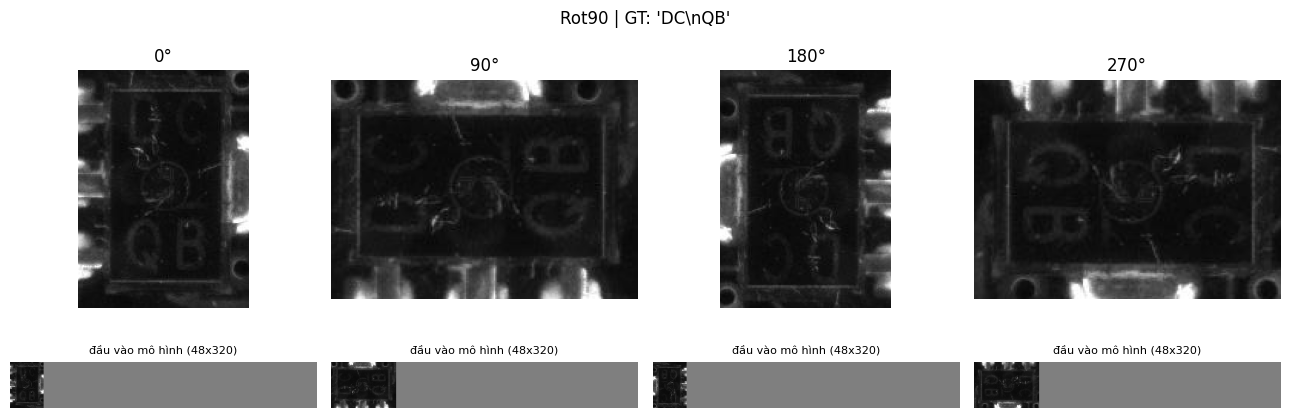

In [8]:
# xem thử Rot90 và đầu vào thực tế của mô hình (sau RecResizeImg: 48 x 320, đệm bên phải)
def show_rot90_and_input(view="DF_path", i=0):
    ops = create_operators([{"DecodeImage": {"img_mode": "BGR", "channel_first": False}},
                            {"RecResizeImg": {"image_shape": list(CFG.rec_image_shape)}}], {})
    p = train_df[view + "_abs"][i]
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
    for c, ang in enumerate((0, 90, 180, 270)):
        raw = cv2.imread(p, cv2.IMREAD_COLOR)
        rot = np.ascontiguousarray(np.rot90(raw, ang // 90))
        axes[0, c].imshow(rot[..., ::-1]); axes[0, c].set_title(f"{ang}°"); axes[0, c].axis("off")
        out = transform({"image": cv2.imencode(".png", rot)[1].tobytes()}, ops)
        axes[1, c].imshow(out["image"] if out["image"].ndim == 2 else np.clip(out["image"].transpose(1, 2, 0) * 0.5 + 0.5, 0, 1))
        axes[1, c].set_title("đầu vào mô hình (48x320)", fontsize=8); axes[1, c].axis("off")
    plt.suptitle(f"Rot90 | GT: {train_df[CFG.label_col][i]!r}"); plt.tight_layout(); plt.show()

show_rot90_and_input()

## 5. Các metric đánh giá (evaluator chung)

Toàn bộ metric nằm trong **`evaluator.py`** (cell ngay bên dưới ghi file này ra đĩa). Cả nhóm phải dùng đúng một bản. Kiểm tra bằng selftest 20 mẫu cố định: `selftest_digest()` phải bằng `EXPECTED_SELFTEST_HASH`.

| Metric | Cách tính | Tốt khi |
|---|---|---|
| **CER** *(metric chính)* | **Corpus-level**: tổng edit distance ký tự / tổng số ký tự ground truth | Thấp |
| **WER** | Tokenization cố định `str.split()`; tổng edit distance từ / tổng số từ ground truth | Thấp |
| **SeqAcc** | Tỉ lệ mẫu khớp 100% (kể cả khoảng trắng, xuống dòng, hoa/thường) | Cao |
| **NED** | Trung bình theo mẫu của `edit_dist / max(len(gt), len(pred), 1)`. `1-NED` = `1 - NED` | Thấp (NED) |
| Phụ | CharAcc, Acc≤1edit, LineAcc, Sub/Del/Ins rate, EmptyPred_rate | |
| **Hiệu năng** | Số tham số, **FPS** (suy luận, đã loại thời gian nạp ảnh), **peak VRAM** (suy luận và train) | |

**Hai chế độ:** `strict` (nguyên chuỗi, là chế độ báo cáo chính) và `no_ws` (bỏ khoảng trắng và xuống dòng, chỉ để chẩn đoán).

**Chọn checkpoint:** val CER (strict) thấp nhất. Hòa (chênh ≤ 1e-6) → val loss thấp hơn. Vẫn hòa → giữ epoch sớm hơn. **Không bao giờ chọn theo test.**

In [9]:
%%writefile evaluator.py
"""evaluator.py -- EVALUATOR CHUNG cho cả nhóm.

KHÔNG sửa file này sau khi đã bắt đầu so sánh. Mọi thành viên phải dùng đúng bản này
(kiểm tra bằng selftest_digest() == EXPECTED_SELFTEST_HASH trên 20 mẫu cố định).

Định nghĩa cố định
- CER (metric chính): corpus-level = tổng edit distance ký tự / tổng số ký tự ground truth.
- WER: tokenization = str.split() (tách theo mọi khoảng trắng và xuống dòng);
       corpus-level = tổng edit distance từ / tổng số từ ground truth.
- SeqAcc: tỉ lệ mẫu dự đoán khớp 100% ground truth (kể cả khoảng trắng, xuống dòng, hoa/thường).
- NED: trung bình theo mẫu của edit_dist / max(len(gt), len(pred), 1)  (thấp là tốt); 1-NED = 1 - NED.
- mode "strict": so khớp nguyên chuỗi.  mode "no_ws": bỏ mọi khoảng trắng/xuống dòng trước khi so.
- Edit distance: Levenshtein (chèn / xoá / thay đều chi phí 1) trên ký tự (hoặc trên từ cho WER).
"""
import hashlib
import json
import math

import numpy as np

EVALUATOR_VERSION = "1.0.0"


def edit_ops(ref, hyp):
    """Levenshtein + backtrace -> (dist, S, D, I, danh sách cặp thay thế (ref_char, hyp_char))."""
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=np.int32)
    dp[:, 0] = np.arange(n + 1)
    dp[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            dp[i, j] = min(dp[i - 1, j] + 1, dp[i, j - 1] + 1, dp[i - 1, j - 1] + cost)
    i, j, S, D, I, subs = n, m, 0, 0, 0, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and dp[i, j] == dp[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                S += 1
                subs.append((ref[i - 1], hyp[j - 1]))
            i -= 1
            j -= 1
        elif i > 0 and dp[i, j] == dp[i - 1, j] + 1:
            D += 1
            i -= 1
        else:
            I += 1
            j -= 1
    return int(dp[n, m]), S, D, I, subs


def word_tokens(s):
    """Tokenization cố định cho WER."""
    return s.split()


def line_accuracy(gts, preds):
    ok = tot = 0
    for g, p in zip(gts, preds):
        gl, pl = g.split("\n"), p.split("\n")
        for k, line in enumerate(gl):
            tot += 1
            ok += int(k < len(pl) and pl[k] == line)
    return ok / max(tot, 1)


def compute_metrics(gts, preds, mode="strict"):
    gts, preds = list(gts), list(preds)
    if len(gts) != len(preds):
        raise ValueError(f"len(gts)={len(gts)} != len(preds)={len(preds)}")
    if mode not in ("strict", "no_ws"):
        raise ValueError("mode phải là 'strict' hoặc 'no_ws'")
    empty_rate = float(np.mean([len(p) == 0 for p in preds])) if preds else float("nan")
    if mode == "no_ws":
        gts = ["".join(g.split()) for g in gts]
        preds = ["".join(p.split()) for p in preds]
    n, total_len = len(gts), max(sum(len(g) for g in gts), 1)
    S = D = I = tot_d = exact = le1 = w_err = w_tot = 0
    ned_sum = 0.0
    for g, p in zip(gts, preds):
        d, s, de, ins, _ = edit_ops(g, p)
        S += s
        D += de
        I += ins
        tot_d += d
        exact += int(g == p)
        le1 += int(d <= 1)
        ned_sum += d / max(len(g), len(p), 1)
        if mode == "strict":
            gw, pw = word_tokens(g), word_tokens(p)
            w_err += edit_ops(gw, pw)[0]
            w_tot += len(gw)
    cer = tot_d / total_len
    ned = ned_sum / max(n, 1)
    return {
        "CER": cer,
        "WER": (w_err / max(w_tot, 1)) if mode == "strict" else float("nan"),
        "SeqAcc": exact / max(n, 1),
        "NED": ned,
        "1-NED": 1 - ned,
        "CharAcc": max(0.0, 1 - cer),
        "Acc<=1edit": le1 / max(n, 1),
        "Sub_rate": S / total_len,
        "Del_rate": D / total_len,
        "Ins_rate": I / total_len,
        "EmptyPred_rate": empty_rate,
        "LineAcc": line_accuracy(gts, preds) if mode == "strict" else float("nan"),
        "n_samples": n,
        "n_chars": total_len,
    }


# ---------------------------------------------------------------- selftest: 20 mẫu cố định (gt, pred)
SELFTEST_PAIRS = [
    ("O43Z", "043Z"),
    ("SS24", "SS24"),
    ("AB\nCD", "AB\nCD"),
    ("AB\nCD", "ABCD"),
    ("AB CD", "AB  CD"),
    ("", ""),
    ("XYZ", ""),
    ("", "Q"),
    ("abc12", "ABC12"),
    ("JA-80", "JA-80\\"),
    ("E8002D\ncjc1w1", "E8002D\ncjc1w1"),
    ("E8002D\ncjc1w1", "E8002D cjc1w1"),
    ("1234567890", "123456789"),
    ("A+B-C.D", "A+B-C.D"),
    ("LINE1\nLINE2\nLINE3", "LINE1\nLINE3"),
    ("HELLO WORLD", "HELO WORLD"),
    ("0000", "OOOO"),
    ("AAAA", "AAAAAAAA"),
    ("X", "Y"),
    ("MULTI WORD LABEL 42", "MULTI WORD LABEL 42 "),
]


def _clean(v):
    if isinstance(v, float):
        return None if math.isnan(v) else round(v, 10)
    return v


def selftest_digest():
    """SHA256 của toàn bộ metric (strict + no_ws) trên 20 mẫu cố định."""
    gts = [g for g, _ in SELFTEST_PAIRS]
    preds = [p for _, p in SELFTEST_PAIRS]
    payload = {m: {k: _clean(v) for k, v in compute_metrics(gts, preds, m).items()} for m in ("strict", "no_ws")}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode("utf-8")).hexdigest()


EXPECTED_SELFTEST_HASH = "7a5c7a5670ddec14aaf2ceb553b16fc635c0d67cdd2c5294047ac26bd54777ed"

if __name__ == "__main__":
    d = selftest_digest()
    print("selftest digest:", d)
    print("PASS" if d == EXPECTED_SELFTEST_HASH else "FAIL: evaluator khác bản chuẩn")

Writing evaluator.py


In [10]:
import importlib
sys.path.insert(0, os.getcwd())
import evaluator; importlib.reload(evaluator)
from evaluator import (edit_ops, compute_metrics, line_accuracy, selftest_digest,
                       EXPECTED_SELFTEST_HASH, EVALUATOR_VERSION)

EVALUATOR_HASH = sha256_file("evaluator.py")
_d = selftest_digest()
print("evaluator", EVALUATOR_VERSION, "| sha256(evaluator.py):", EVALUATOR_HASH[:16])
print("selftest 20 mẫu:", _d[:16], "| chuẩn:", EXPECTED_SELFTEST_HASH[:16], "->", "PASS" if _d == EXPECTED_SELFTEST_HASH else "FAIL")
assert _d == EXPECTED_SELFTEST_HASH, "Evaluator khác bản chuẩn của nhóm! Dùng đúng evaluator.py chung."
print(compute_metrics(["O43Z", "SS24"], ["043Z", "SS24"]))

evaluator 1.0.0 | sha256(evaluator.py): 4b9c4d46fd98ef9c
selftest 20 mẫu: 7a5c7a5670ddec14 | chuẩn: 7a5c7a5670ddec14 -> PASS
{'CER': 0.125, 'WER': 0.5, 'SeqAcc': 0.5, 'NED': 0.125, '1-NED': 0.875, 'CharAcc': 0.875, 'Acc<=1edit': 1.0, 'Sub_rate': 0.125, 'Del_rate': 0.0, 'Ins_rate': 0.0, 'EmptyPred_rate': 0.0, 'LineAcc': 0.5, 'n_samples': 2, 'n_chars': 8}


### Kiểm tra trước khi chạy GPU

Chạy cell dưới và **gửi kết quả cho cả nhóm**. Đối chiếu: (1) selftest PASS ở cell trên, (2) `SPLIT HASH` giống nhau, (3) phân bố độ dài nhãn / số dòng / hướng chữ / board của val không lệch bất thường so với train. **Không sửa split sau khi bắt đầu so sánh.**

> `train.csv` không có cột hướng chữ, nên "hướng chữ" được đo bằng **proxy**: tỉ lệ ảnh DF dạng đứng (cao > rộng) và median tỉ lệ w/h của ảnh gốc.

In [11]:
def label_stats(d):
    L = d[CFG.label_col]; nl = L.str.count("\n") + 1; ln = L.str.len()
    return {"n": len(d), "len_mean": ln.mean(), "len_p50": ln.median(), "len_p95": ln.quantile(0.95), "len_max": ln.max(),
            "lines_mean": nl.mean(), "multiline_ratio": (nl > 1).mean(), "empty_ratio": (L == "").mean(),
            "has_lower_ratio": L.str.contains("[a-z]").mean()}

def aspect_stats(d):
    wh = []
    for p in d[CFG.all_views[0] + "_abs"]:
        with Image.open(p) as im:                    # chỉ đọc header, không giải mã ảnh
            wh.append(im.size)
    ar = np.array([w / h for w, h in wh])
    return {"portrait_ratio(proxy hướng chữ)": float((ar < 1).mean()), "aspect_w/h_median": float(np.median(ar))}

groups = {"train (gốc+_aug)": train_df, "train (chỉ gốc)": train_df[~train_df.is_aug], "val (gốc)": val_df, "test": test_df}
stats = pd.DataFrame({k: {**label_stats(d), **aspect_stats(d)} for k, d in groups.items()})
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
display(stats)
stats.to_csv(CFG.out_dir / "precheck_label_stats.csv")

# ---- board trong val vs train (capture gốc) ----
bt = pd.crosstab(train_all[~train_all.is_aug].board, train_all[~train_all.is_aug].split)
for c in ("train", "val"):
    if c not in bt: bt[c] = 0
bt = bt[["train", "val"]]
print(f"số board: {len(bt)} | board chỉ có ở val: {int(((bt.train == 0) & (bt.val > 0)).sum())} | "
      f"board chỉ có ở train: {int(((bt.val == 0) & (bt.train > 0)).sum())}")
display(bt.T)
bt.to_csv(CFG.out_dir / "precheck_board_counts.csv")

print("\nSPLIT HASH   :", SPLIT_HASH)
print("EVALUATOR    :", EVALUATOR_HASH[:16], "| selftest PASS")
print("Test không dùng ở bước này. CFG.final_test =", CFG.final_test)

,train (gốc+_aug),train (chỉ gốc),val (gốc),test
n,1908.000,954.000,106.000,455.000
len_mean,9.218,9.218,8.868,8.820
len_p50,5.000,5.000,5.000,5.000
len_p95,29.650,29.350,33.500,27.600
len_max,45.000,45.000,44.000,47.000
lines_mean,1.734,1.734,1.698,1.732
multiline_ratio,0.466,0.466,0.377,0.490
empty_ratio,0.009,0.009,0.009,0.009
has_lower_ratio,0.001,0.001,0.000,0.007
portrait_ratio(proxy hướng chữ),0.525,0.525,0.679,0.574


số board: 34 | board chỉ có ở val: 0 | board chỉ có ở train: 3


board,05,07,100,101,102,103,104,105,106,107,...,66,74,76,77,80,82,85,90,91,92
split,,,,,,,,,,,,,,,,,,,,,
train,1,29,43,27,27,26,21,16,71,32,...,9,44,14,20,44,39,7,20,8,3
val,0,2,4,5,2,1,4,2,14,4,...,0,4,3,4,7,4,1,2,1,0



SPLIT HASH   : 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
EVALUATOR    : 4b9c4d46fd98ef9c | selftest PASS
Test không dùng ở bước này. CFG.final_test = False


## 6. Hàm train / evaluate (vòng train dựng trên các module của PaddleOCR)

Vòng train **mô phỏng `tools/program.py::train` của PaddleOCR**: cùng `build_dataloader`, `build_model`, `build_loss` (`MultiLoss` = CTC + NRTR), `build_optimizer` (Adam + Cosine + warmup, scheduler bước theo iteration), `load_pretrained_params`. Khác biệt có chủ đích:

- **Đánh giá mỗi epoch bằng `evaluator.py` chung trên toàn bộ val** (kể cả nhãn rỗng/quá dài, giữ nguyên hoa/thường): CER corpus-level, WER, SeqAcc. Đây là thứ dùng để chọn checkpoint, **không** phải metric `acc` của PaddleOCR (nó bỏ qua các mẫu không mã hóa được và đưa về chữ thường tùy cấu hình).
- **Chọn checkpoint:** val CER thấp nhất. Hòa (≤ 1e-6) → val loss thấp hơn → giữ epoch sớm hơn.
- **val loss** = CTC loss tính từ xác suất đầu ra ở chế độ eval, trên các mẫu val mã hóa được (chỉ dùng để phá hòa và vẽ biểu đồ).
- **Precision:** AMP O1 (`paddle.amp.auto_cast`) + `GradScaler` cho FP16; BF16 không cần scaler.
- Mỗi run ghi vào `outputs_paddleocr/<model>_<view>_s<seed>/`: `config.json`, `env.json`, `model_card.json`, `paddle_config.yml`, `train.log`, `history.csv`, `best.pdparams`, `val_predictions.csv`, `val_metrics.json` (và `test_*` khi chạy test).

In [12]:
# ---------------------------------------------------------------- AMP
def autocast_ctx():
    p = CFG.precision_resolved
    if p == "fp32" or not USE_GPU:
        return contextlib.nullcontext()
    return paddle.amp.auto_cast(enable=True, level="O1", dtype="float16" if p == "fp16" else "bfloat16")

def make_scaler():
    return paddle.amp.GradScaler(init_loss_scaling=1024.0) if (CFG.precision_resolved == "fp16" and USE_GPU) else None

def to_f32(x):
    if isinstance(x, dict):  return {k: to_f32(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return type(x)(to_f32(v) for v in x)
    if isinstance(x, paddle.Tensor) and x.dtype in (paddle.float16, paddle.bfloat16): return x.astype("float32")
    return x

# ---------------------------------------------------------------- lưu vết run
def get_git_commit():
    if CFG.git_commit:
        return CFG.git_commit
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL, timeout=10).decode().strip()
    except Exception:
        return "unknown (không có git: điền CFG.git_commit)"

_ENV = {}
def get_env_info():
    if not _ENV:
        try:
            freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], stderr=subprocess.DEVNULL, timeout=120).decode().splitlines()
        except Exception:
            freeze = []
        _ENV.update(python=sys.version, platform=platform.platform(), paddle=paddle.__version__,
                    paddle_cuda=paddle.version.cuda() if USE_GPU else None, paddle_cudnn=paddle.version.cudnn() if USE_GPU else None,
                    numpy=np.__version__, pandas=pd.__version__, pillow=PIL.__version__, opencv=cv2.__version__,
                    gpu=paddle.device.cuda.get_device_name(0) if USE_GPU else None, pip_freeze=freeze)
    return _ENV

def jsonable(v):
    if isinstance(v, Path): return str(v)
    if isinstance(v, (set, frozenset)): return sorted(v)
    if isinstance(v, (tuple, list)): return [jsonable(x) for x in v]
    if isinstance(v, dict): return {str(k): jsonable(x) for k, x in v.items()}
    return v

def cfg_dict():
    return {k: jsonable(v) for k, v in vars(CFG).items() if not k.startswith("_")}

def save_run_meta(run_dir, view, seed, pcfg, card):
    meta = dict(created=datetime.datetime.now().isoformat(timespec="seconds"), view=VIEW_NAME[view], seed=seed,
                split_mode=CFG.split_mode, split_hash=SPLIT_HASH, git_commit=get_git_commit(),
                evaluator_version=EVALUATOR_VERSION, evaluator_sha256=EVALUATOR_HASH, data_sha256=DATA_HASHES,
                precision=CFG.precision_resolved, rec_model=CFG.rec_model, model_card=card, config=cfg_dict())
    (run_dir / "config.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    (run_dir / "env.json").write_text(json.dumps(get_env_info(), ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    (run_dir / "model_card.json").write_text(json.dumps(card, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    (run_dir / "paddle_config.yml").write_text(yaml.safe_dump(jsonable(pcfg), allow_unicode=True, sort_keys=False), encoding="utf-8")

# ---------------------------------------------------------------- suy luận trên TOÀN BỘ dòng (không bỏ mẫu nào)
def infer_ops(pcfg):
    return create_operators([{"DecodeImage": {"img_mode": "BGR", "channel_first": False}},
                             {"RecResizeImg": {"image_shape": list(CFG.rec_image_shape)}},
                             {"KeepKeys": {"keep_keys": ["image"]}}], pcfg["Global"])

def load_batch(paths, ops):
    imgs = []
    for p in paths:
        with open(p, "rb") as f:
            imgs.append(transform({"image": f.read()}, ops)[0])
    return paddle.to_tensor(np.stack(imgs).astype("float32"))

@paddle.no_grad()
def predict(model, post, pcfg, df, view, bs=64):
    """Trả về danh sách chuỗi dự đoán, '\n' đã được khôi phục, đúng thứ tự dòng của df."""
    model.eval()
    ops, preds = infer_ops(pcfg), []
    paths = df[view + "_abs"].tolist()
    for i in range(0, len(paths), bs):
        x = load_batch(paths[i:i + bs], ops)
        with autocast_ctx():
            out = model(x)
        res = post(to_f32(out))
        preds += [t.replace(NL_CHAR, "\n") for t, _ in res]
    return preds

@paddle.no_grad()
def val_ctc_loss(model, val_loader):
    """CTC loss trung bình theo mẫu từ xác suất eval (log của softmax), chỉ trên mẫu mã hóa được."""
    model.eval()
    tot, n = 0.0, 0
    for batch in val_loader:
        with autocast_ctx():
            probs = to_f32(model(batch[0]))
        if isinstance(probs, dict): probs = probs.get("ctc", list(probs.values())[0])
        logp = paddle.log(paddle.clip(probs, 1e-8, 1.0)).transpose([1, 0, 2])               # [T, B, C]
        T, B = logp.shape[0], logp.shape[1]
        loss = F.ctc_loss(logp, batch[1].astype("int32"), paddle.full([B], T, dtype="int64"), batch[3].astype("int64"),     # batch = [image, label_ctc, label_gtc, length, valid_ratio]
                          blank=0, reduction="sum")
        tot += float(loss); n += B
    return tot / max(n, 1)

def measure_efficiency(model, pcfg, df, view, bs=64):
    """Số tham số, FPS (chỉ thời gian forward, ảnh đã được tiền xử lý và nằm sẵn trên thiết bị) và peak VRAM suy luận (MB)."""
    model.eval()
    out = {"params_M": sum(int(np.prod(p.shape)) for p in model.parameters()) / 1e6, "FPS": float("nan"), "peak_VRAM_infer_MB": float("nan")}
    ops = infer_ops(pcfg)
    paths = df[view + "_abs"].tolist()
    batches = [load_batch(paths[i:i + bs], ops) for i in range(0, len(paths), bs)]
    n = sum(int(b.shape[0]) for b in batches)
    with paddle.no_grad():
        with autocast_ctx(): model(batches[0])                      # warm-up
        if USE_GPU:
            paddle.device.cuda.synchronize()
            try: paddle.device.cuda.reset_max_memory_allocated()
            except Exception: pass
        t0 = time.perf_counter()
        for b in batches:
            with autocast_ctx(): model(b)
        if USE_GPU: paddle.device.cuda.synchronize()
        dt = time.perf_counter() - t0
    out["FPS"] = n / dt
    if USE_GPU:
        try: out["peak_VRAM_infer_MB"] = paddle.device.cuda.max_memory_allocated() / 2**20
        except Exception: pass
    return out

# ---------------------------------------------------------------- train một (view, seed)
def train_view(view, seed):
    CFG.seed = seed
    set_seed(seed)
    name = VIEW_NAME[view]
    run_dir = CFG.out_dir / f"{CFG.rec_model}_{name}_s{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    logf = open(run_dir / "train.log", "w", encoding="utf-8")
    def P(*a):
        msg = " ".join(str(x) for x in a); print(msg); logf.write(msg + "\n"); logf.flush()

    train_txt, val_txt = run_dir / "train.txt", run_dir / "val.txt"
    n_tr, n_va = write_label_file(train_df, view, train_txt), write_label_file(val_df, view, val_txt)
    pcfg = make_paddle_config(view, run_dir, train_txt, val_txt)
    plog = get_logger(log_file=str(run_dir / "paddleocr.log"))
    post, model, loss_fn = build_all(pcfg)

    card = copy.deepcopy(MODEL_CARD)
    n_params = sum(int(np.prod(p.shape)) for p in model.parameters())
    card["model_stats"] = {"params_M": n_params / 1e6}
    if PRETRAINED_PATH is not None:
        card["model_stats"].update(load_pretrained_report(model, PRETRAINED_PATH))
    print_model_card(card)

    train_loader = build_dataloader(pcfg, "Train", DEVICE, plog, seed)
    val_loader   = build_dataloader(pcfg, "Eval",  DEVICE, plog, seed)
    optimizer, lr_scheduler, wd_scheduler = build_optimizer(pcfg["Optimizer"], epochs=CFG.epochs, step_each_epoch=len(train_loader), model=model)   # v3.7.0 trả về 3 giá trị
    scaler = make_scaler()
    save_run_meta(run_dir, view, seed, pcfg, card)

    val_gts = val_df[CFG.label_col].tolist()
    sub_df = train_df.sample(min(256, len(train_df)), random_state=seed).reset_index(drop=True)
    sub_gts = sub_df[CFG.label_col].tolist()
    P(f"[{name}] {CFG.rec_model} | seed {seed} | precision {CFG.precision_resolved} | split {SPLIT_HASH[:12]} | "
      f"train {n_tr} (mã hóa được ~{len(train_loader) * CFG.batch_size}/epoch) | val {n_va}")

    hist = {k: [] for k in ["train_loss", "val_loss", "train_cer", "val_cer", "val_wer", "val_seqacc", "val_empty", "lr"]}
    best = {"cer": float("inf"), "wer": float("inf"), "loss": float("inf"), "epoch": 0, "seqacc": 0.0}
    ckpt, bad = run_dir / "best.pdparams", 0
    if USE_GPU:
        try: paddle.device.cuda.reset_max_memory_allocated()
        except Exception: pass
    t0 = time.time()

    for ep in range(1, CFG.epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for batch in train_loader:
            with autocast_ctx():
                preds = model(batch[0], data=batch[1:])
            loss = loss_fn(to_f32(preds), batch)["loss"]
            if scaler is not None:
                scaled = scaler.scale(loss); scaled.backward(); scaler.minimize(optimizer, scaled)
            else:
                loss.backward(); optimizer.step()
            optimizer.clear_grad()
            if lr_scheduler is not None:
                lr_scheduler.step()
            if wd_scheduler is not None:
                wd_scheduler.step()
            tot += float(loss) * int(batch[0].shape[0]); n += int(batch[0].shape[0])
        tr = tot / max(n, 1)

        vp = predict(model, post, pcfg, val_df, view)
        sp = predict(model, post, pcfg, sub_df, view)
        vl = val_ctc_loss(model, val_loader)
        m  = compute_metrics(val_gts, vp, "strict")
        tm = compute_metrics(sub_gts, sp, "strict")
        cur_lr = float(optimizer.get_lr())
        for k, v in zip(hist, [tr, vl, tm["CER"], m["CER"], m["WER"], m["SeqAcc"], m["EmptyPred_rate"], cur_lr]):
            hist[k].append(v)

        improved = (m["CER"] < best["cer"] - 1e-6) or (abs(m["CER"] - best["cer"]) <= 1e-6 and vl < best["loss"])
        if improved:
            best.update(cer=m["CER"], wer=m["WER"], loss=vl, epoch=ep, seqacc=m["SeqAcc"])
            paddle.save(model.state_dict(), str(ckpt)); bad = 0
        else:
            bad += 1
        if ep < CFG.min_epochs:
            bad = 0

        if ep == 1 or ep % 5 == 0 or improved:
            P(f"[{name}] ep {ep:3d} | loss tr {tr:.3f} val {vl:.3f} | CER tr {tm['CER']:.3f} val {m['CER']:.3f} | "
              f"val WER {m['WER']:.3f} | val SeqAcc {m['SeqAcc']:.3f} | empty {m['EmptyPred_rate']:.2f} | lr {cur_lr:.1e}{'  *' if improved else ''}")
        if ep == 30 and m["EmptyPred_rate"] > 0.99:
            P(f"[{name}] cảnh báo: sau 30 epoch mô hình vẫn dự đoán rỗng. Kiểm tra nạp pretrained, lr, nhãn.")
        if bad >= CFG.patience:
            P(f"[{name}] early stop ở epoch {ep}"); break

    train_secs = time.time() - t0
    best["peak_VRAM_train_MB"] = float("nan")
    if USE_GPU:
        try: best["peak_VRAM_train_MB"] = paddle.device.cuda.max_memory_allocated() / 2**20
        except Exception: pass
    best["train_seconds"] = train_secs
    model.set_state_dict(paddle.load(str(ckpt)))
    P(f"[{name}] xong sau {train_secs:.0f}s | best epoch {best['epoch']} | val CER {best['cer']:.4f} | val WER {best['wer']:.4f} | "
      f"val SeqAcc {best['seqacc']:.4f} | peak VRAM train {best['peak_VRAM_train_MB']:.0f} MB")

    pd.DataFrame(hist).assign(epoch=np.arange(1, len(hist["train_loss"]) + 1)).to_csv(run_dir / "history.csv", index=False)
    vp = predict(model, post, pcfg, val_df, view)
    pd.DataFrame({"row_id": val_df.row_id, "capture_id": val_df.capture_id, "gt": val_gts, "pred": vp,
                  "edit_dist": [edit_ops(g, p)[0] for g, p in zip(val_gts, vp)]}).to_csv(run_dir / "val_predictions.csv", index=False)
    val_metrics = {mode: compute_metrics(val_gts, vp, mode) for mode in ("strict", "no_ws")}
    (run_dir / "val_metrics.json").write_text(json.dumps({"best": best, "val_loss": best["loss"], **val_metrics}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    logf.close()
    return {"hist": hist, "best": best, "run_dir": run_dir, "view": view, "seed": seed}

def load_best(run):
    """Dựng lại mô hình và nạp checkpoint tốt nhất của một run (dùng cho test)."""
    pcfg = yaml.safe_load(open(run["run_dir"] / "paddle_config.yml", encoding="utf-8"))
    post, model, _ = build_all(pcfg)
    model.set_state_dict(paddle.load(str(run["run_dir"] / "best.pdparams")))
    model.eval()
    return pcfg, post, model

## 8. Train baseline

Chọn `CFG.rec_model` (xem `MODEL_ZOO`) và `CFG.train_views`. `CFG.seeds = [42]` cho screening, khi xác nhận đặt `[42, 43, 44]` (split không đổi vì dùng `CFG.split_seed` riêng).

In [13]:
CFG.rec_model = "PP-OCRv6_medium_rec"          # xem MODEL_ZOO; đổi model thì chạy lại cell "Model nhận dạng..." ở mục 4 để cập nhật model card
CFG.train_views = ["DF_path", "PO_path", "CO_path"]
CFG.seeds = [42]                               # screening. Xác nhận phương án tốt nhất: [42, 43, 44]
print_model_card()
print("views:", CFG.train_views, "| seeds:", CFG.seeds, "| rot90:", CFG.rot90, "| precision:", CFG.precision_resolved)
CFG.final_test = True
runs = {}                                      # (view, seed) -> {hist, best, run_dir, view, seed}
for seed in CFG.seeds:
    for v in CFG.train_views:
        print("=" * 30, VIEW_NAME[v], f"seed {seed}", "=" * 30)
        runs[(v, seed)] = train_view(v, seed)

main_seed = CFG.seeds[0]                       # các biểu đồ bên dưới vẽ theo seed đầu tiên
histories = {v: runs[(v, main_seed)]["hist"] for v in CFG.train_views}
bests     = {v: runs[(v, main_seed)]["best"] for v in CFG.train_views}
print("\nval (checkpoint tốt nhất):")
display(pd.DataFrame([{"view": VIEW_NAME[v], "seed": s, "best_epoch": r["best"]["epoch"], "val_CER": r["best"]["cer"], "val_WER": r["best"]["wer"],
                       "val_SeqAcc": r["best"]["seqacc"], "peak_VRAM_train_MB": r["best"]["peak_VRAM_train_MB"]}
                      for (v, s), r in runs.items()]))

Framework               PaddleOCR 3.7.0 (tag v3.7.0, commit b03f46425e8f)
Engine                  PaddlePaddle 3.2.0 (CUDA 12.6, ghim 3.2.0)
Model nhận dạng         PP-OCRv6_medium_rec | SVTR_LCNet | backbone PPLCNetV4 (medium) | head CTCHead+NRTRHead
Config                  configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml (sha256 5ebee6044fc713b6…)
Từ điển                 ppocr/utils/dict/ppocrv6_dict.txt (18708 ký tự, sha256 b5f2bfe2bdd94484…) | placeholder xuống dòng '¶'
Pretrained              PP-OCRv6_medium_rec_pretrained.pdparams | 221.9 MB | sha256 c4a110423c23739f…
                  https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_pretrained.pdparams
views: ['DF_path', 'PO_path', 'CO_path'] | seeds: [42] | rot90: True | precision: fp16
============================== DF seed 42 ==============================


W1029 04:49:02.366106    23 gpu_resources.cc:114] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 12.8


[2026/10/29 04:49:03] ppocr INFO: load pretrain successful from pretrained/PP-OCRv6_medium_rec_pretrained
Framework               PaddleOCR 3.7.0 (tag v3.7.0, commit b03f46425e8f)
Engine                  PaddlePaddle 3.2.0 (CUDA 12.6, ghim 3.2.0)
Model nhận dạng         PP-OCRv6_medium_rec | SVTR_LCNet | backbone PPLCNetV4 (medium) | head CTCHead+NRTRHead
Config                  configs/rec/PP-OCRv6/PP-OCRv6_medium_rec.yml (sha256 5ebee6044fc713b6…)
Từ điển                 ppocr/utils/dict/ppocrv6_dict.txt (18708 ký tự, sha256 b5f2bfe2bdd94484…) | placeholder xuống dòng '¶'
Pretrained              PP-OCRv6_medium_rec_pretrained.pdparams | 221.9 MB | sha256 c4a110423c23739f…
                  https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv6_medium_rec_pretrained.pdparams
Tham số / nạp pretrained55.59M tham số | nạp 441/441 tensor (bỏ qua do khác shape: 0, thiếu trong file: 0)
[2026/10/29 04:49:03] ppocr INFO: Initialize indexs of datasets:['outputs_p

,view,seed,best_epoch,val_CER,val_WER,val_SeqAcc,peak_VRAM_train_MB
0,DF,42,99,0.427,0.608,0.443,4836.851
1,PO,42,92,0.561,0.810,0.255,5684.140
2,CO,42,100,0.537,0.709,0.330,6531.429


## 9. Biểu đồ loss và metric theo epoch

- Hàng 1: `train_loss` (MultiLoss CTC + NRTR) và `val_loss` (CTC), đường đứt đứng = epoch tốt nhất theo val CER. Hai loss **không cùng thang đo**, chỉ dùng để xem xu hướng.
- Hàng 2: train CER và val CER (khoảng cách cho biết mức overfit), val WER, val SeqAcc và tỉ lệ dự đoán rỗng.

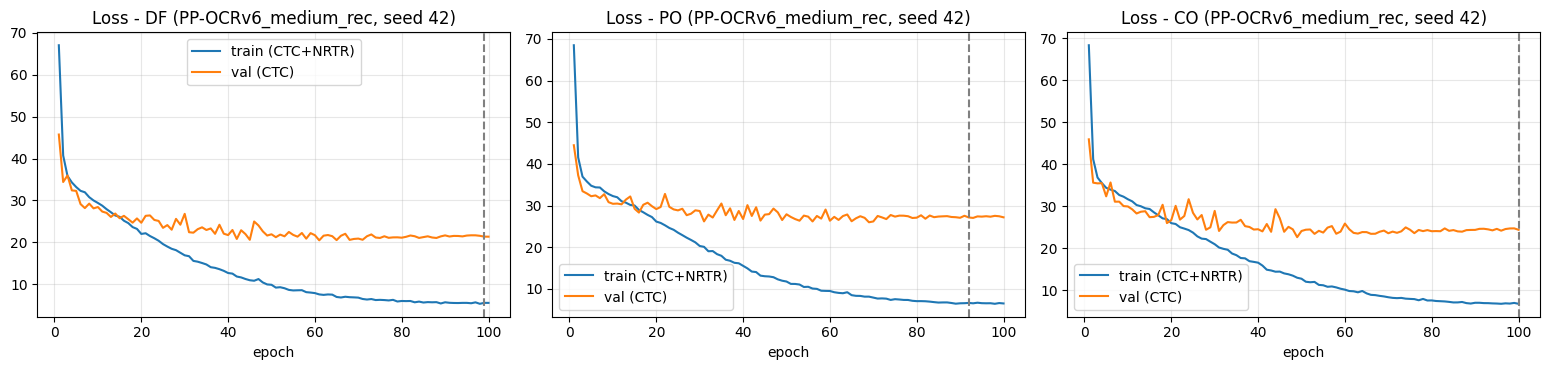

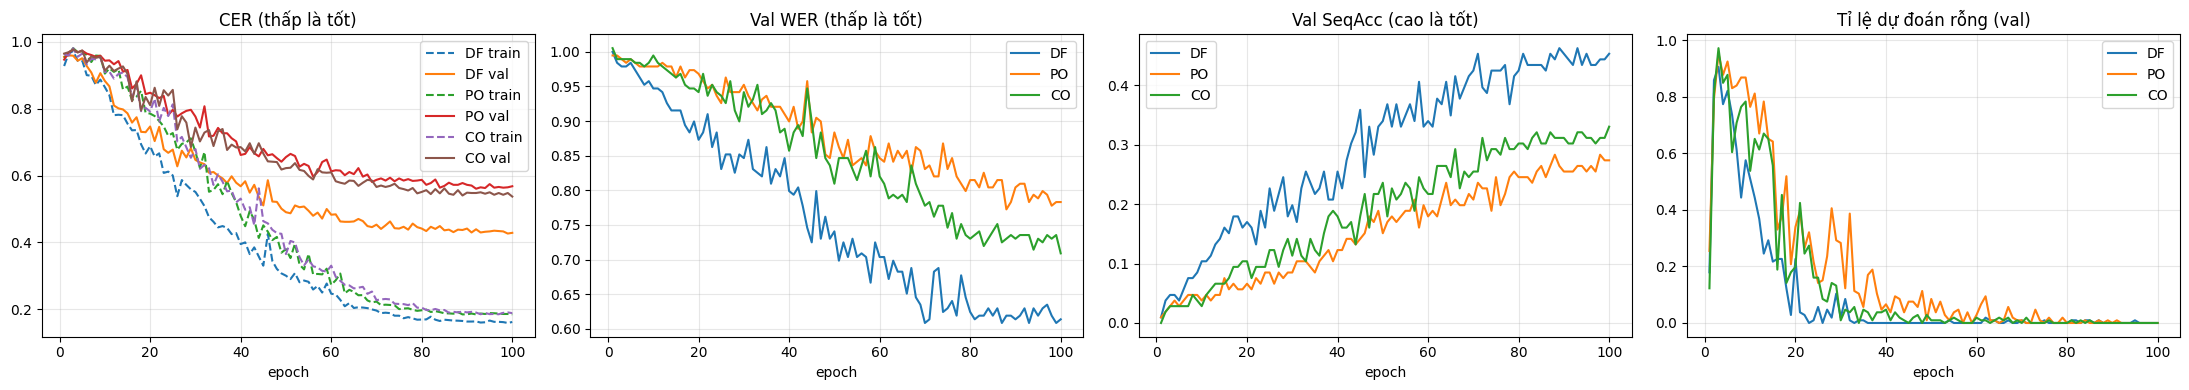

In [14]:
views = CFG.train_views
n = len(views)
fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 3.8), squeeze=False)
for ax, v in zip(axes[0], views):
    h, b = histories[v], bests[v]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="train (CTC+NRTR)"); ax.plot(ep, h["val_loss"], label="val (CTC)")
    ax.axvline(b["epoch"], ls="--", c="gray")
    ax.set_title(f"Loss - {VIEW_NAME[v]} ({CFG.rec_model}, seed {main_seed})"); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(CFG.out_dir / "loss_curves.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for v in views:
    h = histories[v]; ep = np.arange(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_cer"], ls="--", label=f"{VIEW_NAME[v]} train"); axes[0].plot(ep, h["val_cer"], label=f"{VIEW_NAME[v]} val")
    axes[1].plot(ep, h["val_wer"], label=VIEW_NAME[v]); axes[2].plot(ep, h["val_seqacc"], label=VIEW_NAME[v]); axes[3].plot(ep, h["val_empty"], label=VIEW_NAME[v])
for ax, t in zip(axes, ["CER (thấp là tốt)", "Val WER (thấp là tốt)", "Val SeqAcc (cao là tốt)", "Tỉ lệ dự đoán rỗng (val)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(CFG.out_dir / "metric_curves.png", dpi=120); plt.show()

## 10. Đánh giá trên tập test

**Chỉ chạy sau khi đã khóa phương pháp** trên val; khi đó mới đặt `CFG.final_test = True`. Mỗi (view, seed) dùng checkpoint tốt nhất của chính nó và suy luận trên **toàn bộ 455 mẫu** (không lọc). Báo cáo CER (chính), WER, SeqAcc, NED + số tham số, FPS, peak VRAM suy luận.

In [15]:
test_gts = test_df[CFG.label_col].tolist()
rows, test_preds, results_df = [], {}, None

if not CFG.final_test:
    print("CFG.final_test = False -> BỎ QUA test. Khóa phương pháp trên val trước, rồi đặt CFG.final_test = True.")
else:
    for (v, seed), r in runs.items():
        pcfg, post, model = load_best(r)
        preds = predict(model, post, pcfg, test_df, v)
        eff = measure_efficiency(model, pcfg, test_df, v)
        test_preds[(v, seed)] = preds
        mets = {mode: compute_metrics(test_gts, preds, mode) for mode in ("strict", "no_ws")}
        for mode, m in mets.items():
            rows.append({"view": VIEW_NAME[v], "seed": seed, "mode": mode, **m, **eff})
        pd.DataFrame({"row_id": test_df.row_id, "gt": test_gts, "pred": preds,
                      "edit_dist": [edit_ops(g, p)[0] for g, p in zip(test_gts, preds)]}).to_csv(r["run_dir"] / "test_predictions.csv", index=False)
        (r["run_dir"] / "test_metrics.json").write_text(json.dumps({**mets, **eff}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

    results_df = pd.DataFrame(rows)
    pd.set_option("display.float_format", lambda x: f"{x:.4f}")
    show_cols = ["view", "seed", "CER", "WER", "SeqAcc", "NED", "LineAcc", "EmptyPred_rate", "params_M", "FPS", "peak_VRAM_infer_MB"]
    for mode in ("strict", "no_ws"):
        print(f"\n===== Kết quả test | {CFG.rec_model} | mode = {mode} =====")
        display(results_df[results_df["mode"] == mode][show_cols].set_index(["view", "seed"]))
    if len(CFG.seeds) > 1:
        print("\n===== Trung bình ± độ lệch chuẩn theo seed (strict) =====")
        display(results_df[results_df["mode"] == "strict"].groupby("view")[["CER", "WER", "SeqAcc", "NED"]].agg(["mean", "std"]))
    results_df.to_csv(CFG.out_dir / "test_results.csv", index=False)
    pred_df = test_df[["row_id", CFG.label_col] + CFG.all_views].copy()
    for (v, seed), p in test_preds.items():
        pred_df[f"pred_{VIEW_NAME[v]}_s{seed}"] = p
    pred_df.to_csv(CFG.out_dir / "test_predictions.csv", index=False)


===== Kết quả test | PP-OCRv6_medium_rec | mode = strict =====


,,CER,WER,SeqAcc,NED,LineAcc,EmptyPred_rate,params_M,FPS,peak_VRAM_infer_MB
view,seed,,,,,,,,,
DF,42,0.4600,0.6522,0.3516,0.3590,0.3807,0.0088,55.5906,456.1356,1615.2595
PO,42,0.5589,0.7899,0.2110,0.5116,0.2360,0.0198,55.5906,434.6087,1615.2595
CO,42,0.5542,0.7790,0.2527,0.4585,0.2665,0.0044,55.5906,442.3469,1615.2595



===== Kết quả test | PP-OCRv6_medium_rec | mode = no_ws =====


,,CER,WER,SeqAcc,NED,LineAcc,EmptyPred_rate,params_M,FPS,peak_VRAM_infer_MB
view,seed,,,,,,,,,
DF,42,0.4725,NaN,0.3538,0.3673,NaN,0.0088,55.5906,456.1356,1615.2595
PO,42,0.5735,NaN,0.2132,0.5220,NaN,0.0198,55.5906,434.6087,1615.2595
CO,42,0.5652,NaN,0.2549,0.4688,NaN,0.0044,55.5906,442.3469,1615.2595


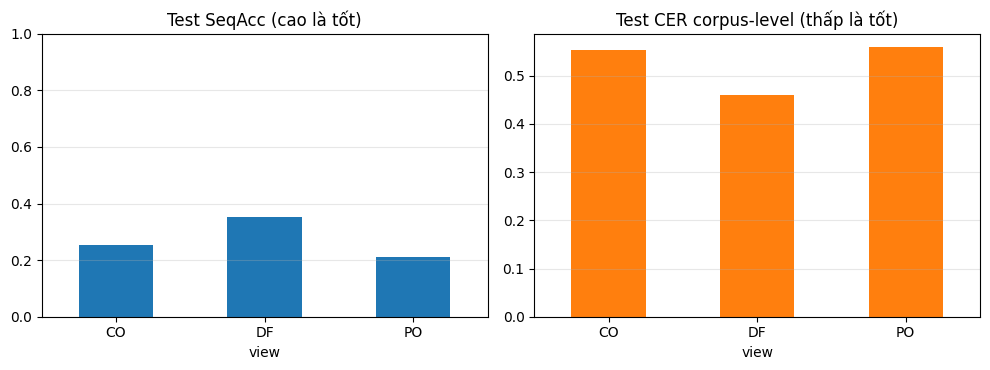

In [16]:
# So sánh nhanh giữa các view (strict, trung bình theo seed)
if results_df is None:
    print("Chưa có kết quả test (CFG.final_test = False).")
else:
    s = results_df[results_df["mode"] == "strict"].groupby("view")[["SeqAcc", "CER"]].mean()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    s["SeqAcc"].plot.bar(ax=axes[0], color="tab:blue", rot=0);  axes[0].set_title("Test SeqAcc (cao là tốt)"); axes[0].set_ylim(0, 1)
    s["CER"].plot.bar(ax=axes[1], color="tab:orange", rot=0);   axes[1].set_title("Test CER corpus-level (thấp là tốt)")
    for ax in axes: ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.show()

## 11. Phân tích lỗi: nhãn 1 dòng so với nhiều dòng

Vì PP-OCR là bộ nhận dạng một dòng (xem phần "Giới hạn đã biết" ở đầu notebook), bảng dưới tách kết quả theo **số dòng của ground truth**, trên **val** (có sẵn sau khi train) và trên **test** (khi `final_test = True`), cùng các cặp ký tự hay nhầm nhất.

In [17]:
def by_lines_table(gts, preds, tag):
    nl = pd.Series([g.count("\n") + 1 for g in gts])
    rows = []
    for name, mask in [("1 dòng", nl == 1), ("nhiều dòng (≥2)", nl >= 2), ("tất cả", nl >= 1)]:
        idx = np.where(mask.values)[0]
        if len(idx) == 0: continue
        m = compute_metrics([gts[i] for i in idx], [preds[i] for i in idx], "strict")
        rows.append({"tập": tag, "nhóm": name, "n": len(idx), "CER": m["CER"], "WER": m["WER"], "SeqAcc": m["SeqAcc"], "LineAcc": m["LineAcc"], "EmptyPred": m["EmptyPred_rate"]})
    return pd.DataFrame(rows)

tabs = []
for (v, seed), r in runs.items():
    if seed != main_seed: continue
    vp = pd.read_csv(r["run_dir"] / "val_predictions.csv", keep_default_na=False)
    t = by_lines_table(vp["gt"].tolist(), vp["pred"].tolist(), f"val ({VIEW_NAME[v]})")
    tabs.append(t)
    if test_preds:
        tabs.append(by_lines_table(test_gts, test_preds[(v, seed)], f"test ({VIEW_NAME[v]})"))
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
display(pd.concat(tabs, ignore_index=True))

if test_preds:
    for v in CFG.train_views:
        cnt = Counter()
        for g, p in zip(test_gts, test_preds[(v, main_seed)]):
            cnt.update(edit_ops("".join(g.split()), "".join(p.split()))[4])
        top = ", ".join(f"{a}→{b} ×{c}" for (a, b), c in cnt.most_common(10)) or "(không có lỗi thay thế)"
        print(f"[{VIEW_NAME[v]}] top nhầm lẫn (test): {top}")

,tập,nhóm,n,CER,WER,SeqAcc,LineAcc,EmptyPred
0,val (DF),1 dòng,66,0.3426,0.5075,0.5455,0.5455,0.0000
1,val (DF),nhiều dòng (≥2),40,0.4572,0.6639,0.2750,0.3684,0.0000
2,val (DF),tất cả,106,0.4266,0.6085,0.4434,0.4333,0.0000
3,test (DF),1 dòng,232,0.3660,0.5431,0.5000,0.5043,0.0172
4,test (DF),nhiều dòng (≥2),223,0.4872,0.6946,0.1973,0.3291,0.0000
5,test (DF),tất cả,455,0.4600,0.6522,0.3516,0.3807,0.0088
6,val (PO),1 dòng,66,0.6295,0.8209,0.3333,0.3333,0.0000
7,val (PO),nhiều dòng (≥2),40,0.5356,0.8033,0.1250,0.1930,0.0000
8,val (PO),tất cả,106,0.5606,0.8095,0.2547,0.2444,0.0000
9,test (PO),1 dòng,232,0.5640,0.7759,0.2974,0.2974,0.0388


[DF] top nhầm lẫn (test): 1→0 ×12, 1→4 ×11, 0→3 ×10, 1→2 ×10, 4→0 ×8, 0→9 ×7, 0→4 ×6, 6→7 ×6, 2→0 ×6, 1→5 ×6
[PO] top nhầm lẫn (test): 1→2 ×14, 4→0 ×12, 2→0 ×10, 1→4 ×10, 1→0 ×8, 9→0 ×7, 4→2 ×7, 3→C ×7, 0→3 ×7, 7→0 ×6
[CO] top nhầm lẫn (test): 1→4 ×11, 4→1 ×10, 0→1 ×10, 7→0 ×10, 1→0 ×10, 2→1 ×9, 1→A ×8, 6→2 ×8, 9→1 ×7, 0→8 ×7


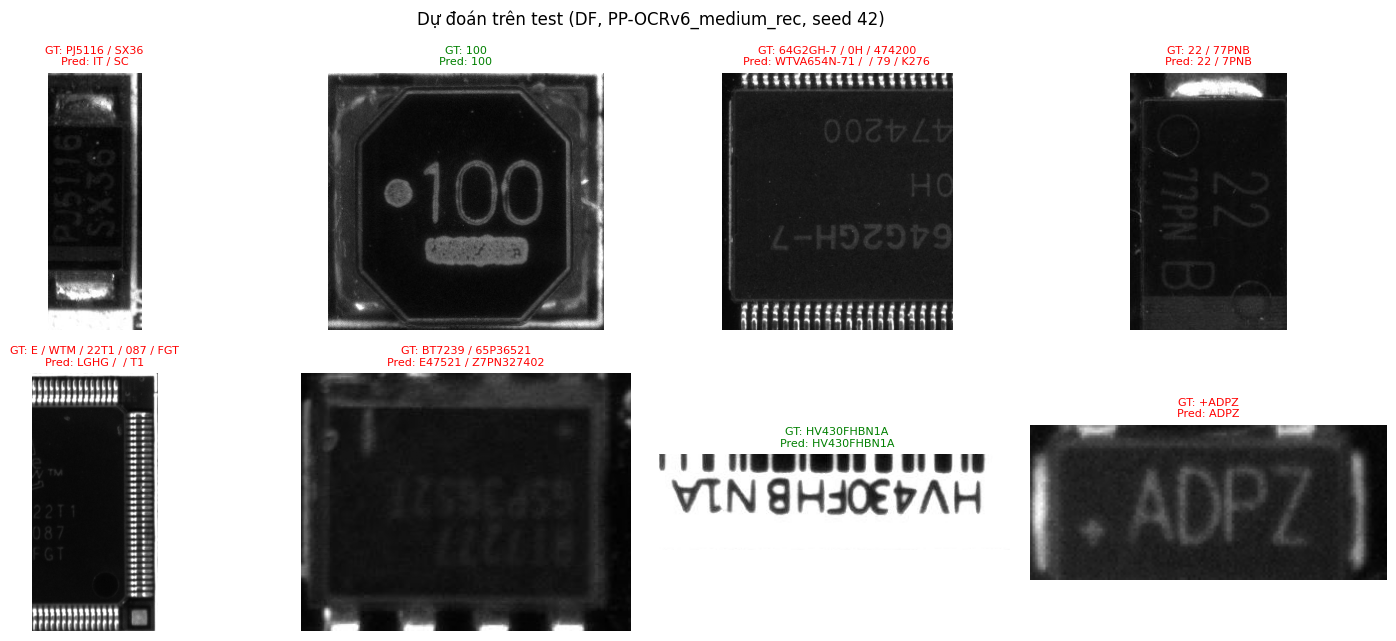

In [18]:
# --- ví dụ dự đoán trên test (đỏ = sai, xanh = đúng) ---
if not test_preds:
    print("Bỏ qua (CFG.final_test = False).")
else:
    def show(s): return s.replace("\n", " / ") if s else "(rỗng)"
    v0 = CFG.train_views[0]; pv = test_preds[(v0, main_seed)]
    idx = np.random.RandomState(1).choice(len(test_df), min(8, len(test_df)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5)); axes = axes.ravel()
    for a, i in zip(axes, idx):
        a.imshow(Image.open(test_df[v0 + "_abs"][i]).convert("L"), cmap="gray")
        ok = pv[i] == test_gts[i]
        a.set_title(f"GT: {show(test_gts[i])}\nPred: {show(pv[i])}", fontsize=8, color="green" if ok else "red"); a.axis("off")
    plt.suptitle(f"Dự đoán trên test ({VIEW_NAME[v0]}, {CFG.rec_model}, seed {main_seed})"); plt.tight_layout(); plt.show()

## 12. Hướng tiếp theo

1. **Đọc bảng mục 11 trước khi đầu tư GPU**: nếu SeqAcc/CER của nhóm "nhiều dòng" kém xa nhóm "1 dòng", nguyên nhân là kiến trúc một dòng của PP-OCR chứ không phải lỗi huấn luyện.
2. **So sánh các cỡ model** (`PP-OCRv6_tiny/small/medium_rec`, `PP-OCRv5_server/mobile_rec`) bằng val CER, cùng seed và cùng `SPLIT HASH`.
3. **Với bố cục nhiều dòng**: PaddleOCR 3.7.0 có `ParseQ` (2D, `configs/rec/rec_vit_parseq.yml`, ViT patch như PARSeq, có trọng số `rec_vit_parseq_real` trong tài liệu `algorithm_rec_parseq`). Vòng train ở mục 6 dựng theo config nên có thể mở rộng sang model đó. Hoặc thêm bước tách dòng (PaddleOCR có text-line detection) rồi nhận dạng từng dòng.
4. **Ablation Rot90** (`CFG.rot90 = True/False`) và `RecAug`, chọn bằng val CER, rồi mới mở test.
5. **Xác nhận** phương án tốt nhất với `CFG.seeds = [42, 43, 44]`.